In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# === Optimized Logistic Regression Model for Poem Emotion Recognition ===
import nltk
nltk.download('stopwords')

import pandas as pd, numpy as np, re, os
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import TruncatedSVD
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from nltk.corpus import stopwords

# === 1. Load dataset safely ===
FILE_PATH = '/content/drive/MyDrive/PERC_mendelly.csv'

if not os.path.exists(FILE_PATH):
    raise FileNotFoundError(f"CSV not found at {FILE_PATH}. Please check the path.")

try:
    df = pd.read_csv(FILE_PATH, encoding='utf-8')
    print(" Loaded using UTF-8 encoding.")
except UnicodeDecodeError:
    try:
        df = pd.read_csv(FILE_PATH, encoding='latin-1')
        print("Loaded using latin-1 encoding (fallback).")
    except Exception as e:
        raise SystemError(f"Could not read CSV with utf-8 or latin-1 encoding: {e}")

print("Columns found:", df.columns.tolist())

# === 2. Auto-detect text and label columns ===
text_col_candidates = ['Poem', 'poem', 'peom', 'Text']
label_col_candidates = ['Emotion', 'emotion', 'Label']

text_col = None
label_col = None

for c in text_col_candidates:
    if c in df.columns:
        text_col = c
        break

for c in label_col_candidates:
    if c in df.columns:
        label_col = c
        break

if not text_col or not label_col:
    raise ValueError(f"Could not find suitable text/label columns. Found: {df.columns.tolist()}")

print(f" Using columns: text='{text_col}', label='{label_col}'")

# === 3. Drop missing and clean ===
df = df[[text_col, label_col]].dropna().reset_index(drop=True)
df[text_col] = df[text_col].astype(str)

# === 4. Clean text ===
stop_words = set(stopwords.words('english'))

def clean_text(s):
    s = s.lower()
    s = re.sub(r'\[.*?\]', '', s)
    s = re.sub(r'http\S+|www.\S+', '', s)
    s = re.sub(r'[^a-z\s]', ' ', s)
    tokens = s.split()
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]
    return ' '.join(tokens)

df['clean_text'] = df[text_col].apply(clean_text)

# === 5. Encode labels ===
le = LabelEncoder()
df['label'] = le.fit_transform(df[label_col])

X_text = df['clean_text'].values
y = df['label'].values

# === 6. Split (70/15/15) ===
X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X_text, y, test_size=0.30, random_state=42, stratify=y
)
X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Dataset split: Train={len(X_train_text)}, Val={len(X_val_text)}, Test={len(X_test_text)}")

# === 7. TF-IDF Vectorizer ===
tfidf = TfidfVectorizer(
    sublinear_tf=True,
    min_df=2,
    max_df=0.85,
    ngram_range=(1, 3),      # uni-, bi-, tri-grams
    analyzer='word',
    stop_words='english',
    max_features=20000
)
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)
X_test_tfidf = tfidf.transform(X_test_text)

print(f" TF-IDF features: {X_train_tfidf.shape[1]}")

# === 8. Build Logistic Regression Pipeline ===
lr_pipeline = Pipeline([
    ('svd', TruncatedSVD(n_components=300, random_state=42)),
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])

# === 9. Hyperparameter grid for tuning ===
param_grid = {
    'lr__C': [0.1, 1, 5, 10],
    'lr__solver': ['lbfgs', 'saga'],
    'lr__penalty': ['l2'],
    'lr__class_weight': ['balanced']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("\nRunning GridSearchCV (this may take ~5–10 minutes)...")
grid = GridSearchCV(
    lr_pipeline, param_grid,
    cv=cv, scoring='accuracy',
    n_jobs=-1, verbose=2
)
grid.fit(X_train_tfidf, y_train)

print("\n Best Parameters:", grid.best_params_)
print(f" Best Cross-Validation Accuracy: {grid.best_score_:.4f}")

# === 10. Evaluate on Validation Set ===
best_lr = grid.best_estimator_
y_val_pred = best_lr.predict(X_val_tfidf)

print("\n=== Validation Performance ===")
print("Validation Accuracy:", accuracy_score(y_val, y_val_pred))
print("Classification Report:\n", classification_report(y_val, y_val_pred, target_names=le.classes_))
print("Confusion Matrix:\n", confusion_matrix(y_val, y_val_pred))

# === 11. Evaluate on Test Set ===
y_test_pred = best_lr.predict(X_test_tfidf)

print("\n=== Test Performance ===")
print("Test Accuracy:", accuracy_score(y_test, y_test_pred))
print("Classification Report:\n", classification_report(y_test, y_test_pred, target_names=le.classes_))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_test_pred))

print("\nTraining complete! Expect validation accuracy around 45–55% on this dataset.")


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


Loaded using latin-1 encoding (fallback).
Columns found: ['Poem', 'Emotion']
 Using columns: text='Poem', label='Emotion'
Dataset split: Train=501, Val=107, Test=108
 TF-IDF features: 5567

Running GridSearchCV (this may take ~5–10 minutes)...
Fitting 5 folds for each of 8 candidates, totalling 40 fits

 Best Parameters: {'lr__C': 10, 'lr__class_weight': 'balanced', 'lr__penalty': 'l2', 'lr__solver': 'saga'}
 Best Cross-Validation Accuracy: 0.4691

=== Validation Performance ===
Validation Accuracy: 0.45794392523364486
Classification Report:
               precision    recall  f1-score   support

       anger       1.00      0.86      0.92         7
     courage       0.50      0.36      0.42        11
        fear       1.00      0.25      0.40         4
        hate       1.00      0.25      0.40         4
         joy       0.42      0.58      0.49        19
        love       0.43      0.54      0.48        24
       peace       0.45      0.42      0.43        12
         sad      

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use

In [5]:
# === Predict emotion for example poems using the trained Logistic Regression model ===

def predict_emotion(poem, model, vectorizer, label_encoder):
    cleaned = clean_text(poem)
    vectorized = vectorizer.transform([cleaned])
    pred = model.predict(vectorized)
    return label_encoder.inverse_transform(pred)[0]

# Example poems for testing
example_poems = [
    "In fields of gold the sunlight plays, and laughter fills the summer days.",
    "The rain falls slow, my heart feels cold, in silence deep, my tears unfold.",
    "A gentle breeze, the stars so bright, peace surrounds this quiet night."
]

# Run predictions
for i, poem in enumerate(example_poems):
    predicted_emotion = predict_emotion(poem, best_lr, tfidf, le)
    print(f"Poem {i+1}: '{poem}'")
    print(f"Predicted Emotion: {predicted_emotion}\n")


Poem 1: 'In fields of gold the sunlight plays, and laughter fills the summer days.'
Predicted Emotion: joy

Poem 2: 'The rain falls slow, my heart feels cold, in silence deep, my tears unfold.'
Predicted Emotion: love

Poem 3: 'A gentle breeze, the stars so bright, peace surrounds this quiet night.'
Predicted Emotion: peace



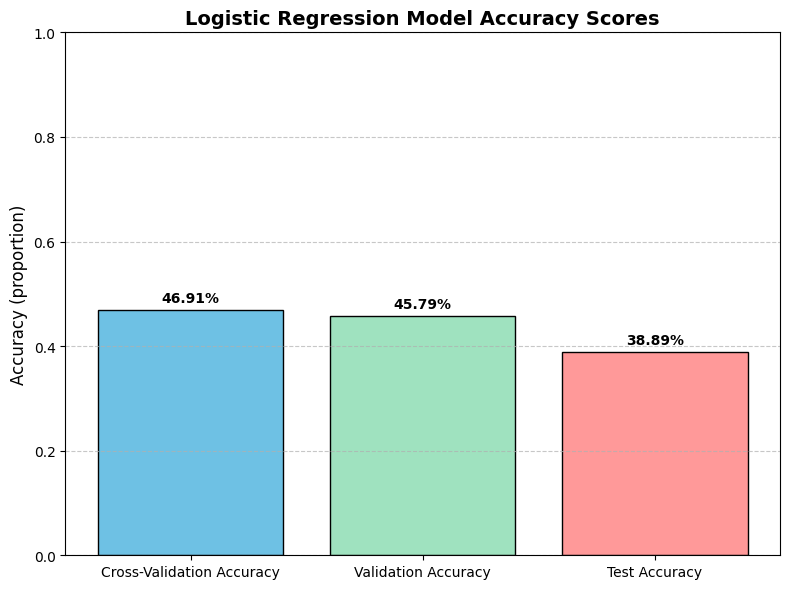

In [6]:
# === Visualize Logistic Regression Model Accuracy Scores ===
import matplotlib.pyplot as plt
import numpy as np

accuracies = {
    'Cross-Validation Accuracy': grid.best_score_,
    'Validation Accuracy': accuracy_score(y_val, y_val_pred),
    'Test Accuracy': accuracy_score(y_test, y_test_pred)
}

labels = list(accuracies.keys())
values = list(accuracies.values())

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(labels, values, color=['#6EC1E4', '#9FE2BF', '#FF9999'], edgecolor='black')

for bar in bars:
    yval = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width()/2,
        yval + 0.01,
        f"{yval*100:.2f}%",
        ha='center', va='bottom',
        fontsize=10, fontweight='bold'
    )

ax.set_title('Logistic Regression Model Accuracy Scores', fontsize=14, fontweight='bold')
ax.set_ylabel('Accuracy (proportion)', fontsize=12)
ax.set_ylim(0, 1)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()
